In [1]:
"""
Train a Random forest model on the iris dataset and plot the results
"""

import numpy as np
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.inspection import DecisionBoundaryDisplay


In [2]:
# Load the iris dataset
data = datasets.load_iris()
#data = datasets.load_wine()
X = data.data[:, [0, 1]]
y = data.target

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Train the model
clf = RandomForestClassifier(n_estimators=1000, random_state=42, n_jobs=4, max_depth=4, criterion='gini')
clf.fit(X_train, y_train)

# Make predictions and compute accuracy
y_pred_train = clf.predict(X_train)
accuracy_train = accuracy_score(y_train, y_pred_train)
print(f'Accuracy on training data: {accuracy_train:.2f}')

y_pred = clf.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy on test data: {accuracy:.2f}')


Accuracy on training data: 0.86
Accuracy on test data: 0.78


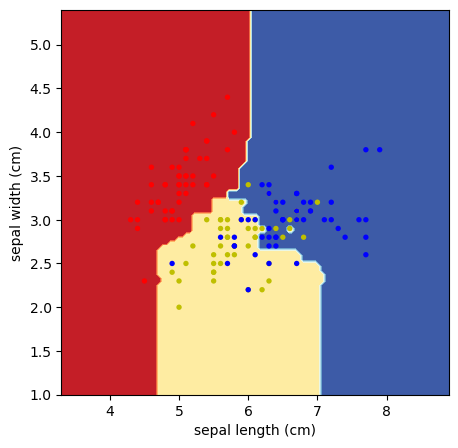

In [3]:
# Plot the decision boundary
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
DecisionBoundaryDisplay.from_estimator(
    clf,
    X,
    cmap=plt.cm.RdYlBu,
    response_method="predict",
    ax=ax,
    xlabel=data.feature_names[0],
    ylabel=data.feature_names[1],
)

plot_colors = "ryb"
for i, color in zip(range(len(np.unique(y))), plot_colors):
    idx = np.where(y == i)
    plt.scatter(
        X[idx, 0],
        X[idx, 1],
        c=color,
        label=data.target_names[i],
        edgecolor="none",
        s=15,
    )